# From a tile to polygons, one block at a time

Most GIS work ends in vectors, and a large raster makes that awkward twice over. The input may not
fit in memory, so it has to be read lazily. Then the polygons seem to need the whole scene, which
means loading the thing you just avoided loading.

Here ManyPred does both without ever holding a full tile. It writes OmniCloudMask's cloud
probability in row blocks, then runs a polygon function over the saved raster one block at a time.
Clouds that cross block edges still come out whole, and we check that against doing it in one go.

One Sentinel-2 tile fits in memory on most machines, so treat it as a demonstration of the method.
Memory here depends on the scene's width and not its height: the
[README](https://github.com/DPIRD-DMA/ManyPred#scenes-larger-than-memory) has a measurement at
1.07 gigapixels.

It uses the image from [the first notebook](01_cloud_mask_whole_tile.ipynb), about 500 MB and no
new download after that one. It takes a few minutes on a GPU, and writes about 2 GB of rasters.

You need `pip install "manypred[geo]" omnicloudmask scipy shapely matplotlib`.

In [1]:
import json
import os
import resource
import sys
from functools import partial
from pathlib import Path
from time import perf_counter
from urllib.request import urlretrieve

import matplotlib.pyplot as plt
import numpy as np
import rasterio
import shapely
import torch
from matplotlib.patches import PathPatch
from matplotlib.path import Path as MplPath
from omnicloudmask.download_models import get_models
from omnicloudmask.model_utils import load_model_from_weights
from rasterio.enums import Resampling
from rasterio.features import shapes
from rasterio.warp import transform_geom
from rasterio.windows import Window
from scipy.ndimage import binary_opening

from manypred import BlockPostprocess, postprocess_blocks, predict_files
from manypred.geo import RasterioReader

DATA = Path(os.environ.get("MANYPRED_DATA", "data"))  # downloads go here
SMOKE = os.environ.get("MANYPRED_NOTEBOOK_SMOKE") == "1"  # the test suite: 160 m pixels, one model
RESOLUTION, PATCH, OVERLAP, BLOCK, HALO = (
    (160, 256, 64, 256, 16) if SMOKE else (10, 1000, 300, 2048, 32)
)
device = "cuda" if torch.cuda.is_available() else "cpu"
plt.rcParams.update({"figure.dpi": 80, "axes.titlesize": 10})

## One file, built without loading it

`RasterioReader` wraps a single raster, so we write the three bands into one GeoTIFF, strip by
strip. If your scenes already come as one file you can skip this.

In [2]:
BUCKET = "https://sentinel-cogs.s3.us-west-2.amazonaws.com/sentinel-s2-l2a-cogs/51/K/YV/2023/1"
SCENE = "S2A_51KYV_20230117_0_L2A"
BANDS = ("B04", "B03", "B8A")  # red, green, near infrared
WORK = DATA / "blocks"
WORK.mkdir(parents=True, exist_ok=True)


def band_path(band):
    url = f"{BUCKET}/{SCENE}/{band}.tif"
    if SMOKE:  # read the file's overviews over the network instead of downloading it
        return url
    path = DATA / "s2" / SCENE / f"{band}.tif"
    if not path.exists():
        path.parent.mkdir(parents=True, exist_ok=True)
        urlretrieve(url, path)
    return path


stack = WORK / f"{SCENE}_stack.tif"
size = 10980 * 10 // RESOLUTION
with rasterio.open(band_path("B04")) as src:
    f = size / src.height
    profile = {
        "driver": "GTiff",
        "height": size,
        "width": size,
        "count": 3,
        "dtype": "uint16",
        "crs": src.crs,
        "tiled": True,
        "blockxsize": 512,
        "blockysize": 512,
        "compress": "lzw",
        "transform": src.transform * src.transform.scale(1 / f),
    }
with rasterio.open(stack, "w", **profile) as dst:
    for index, band in enumerate(BANDS, 1):
        with rasterio.open(band_path(band)) as src:
            scale = src.height / size
            for top in range(0, size, 1024):
                rows = min(1024, size - top)
                strip = src.read(
                    1,
                    window=Window(0, top * scale, src.width, rows * scale),
                    out_shape=(rows, size),
                    resampling=Resampling.bilinear,
                )
                dst.write(strip, index, window=Window(0, top, size, rows))
print(f"{stack.name}: {stack.stat().st_size / 1e9:.2f} GB on disk")

S2A_51KYV_20230117_0_L2A_stack.tif: 0.65 GB on disk


## Predict, written as it goes

`load_func` returns a reader instead of an array, so ManyPred reads each patch when it needs it.
It keeps the nodata map at 1 bit per pixel and hands finished rows to the GeoTIFF writer as soon as
no remaining patch can change them.

`output` takes a function here, because we want one band, thick plus thin cloud. With row-block
writing that function runs per block, so it must work pixel by pixel. This one does.

`merge="cut"` is the setting to notice. Blending averages neighbouring patches, which is right for
a probability you'll read directly. If you'll decode the raster into objects, averaging two
slightly different edges can blur them into a double edge. With `"cut"`, each pixel keeps the
prediction of its most central patch.

Reading and writing compressed files as it goes makes this slower than the in-memory run in the
first notebook, at about 23 s against 6 s for this tile. The memory printed below is what that buys.

In [3]:
def load_lazy(path):
    reader = RasterioReader(path)
    return reader, reader.profile


def cloud_probability(probs):
    return probs[:, 1:3].sum(1, keepdim=True)


models = [
    load_model_from_weights(
        m["timm_model_name"], m["Path"], m["model_library"], torch.device(device)
    )
    for m in get_models()[: 1 if SMOKE else None]
]
settings = dict(
    load_func=load_lazy,
    patch_size=PATCH,
    overlap=OVERLAP,
    batch_size=4,
    nodata=0,
    normalize={"type": "zscore", "scope": "tile"},
    activation="softmax",
    output=cloud_probability,
    overwrite=True,
    progress=False,
)


def peak_gb():
    return resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / 1e6  # kB on Linux, bytes on macOS


before = peak_gb()
start = perf_counter()
[cut] = predict_files(models, [stack], output_dir=WORK / "cut", merge="cut", **settings)
print(f"cut:   {perf_counter() - start:.1f} s, {cut.stat().st_size / 1e6:.0f} MB")
if sys.platform == "linux":
    in_memory = (3 * 2 + 4 * 4) * size**2 / 1e9  # uint16 bands, float32 class probabilities
    print(f"process peak: {before:.1f} GB before predicting, {peak_gb():.1f} GB after")
    print(f"holding the input and a 4-class mosaic would need {in_memory:.1f} GB on its own")
start = perf_counter()
[blend] = predict_files(models, [stack], output_dir=WORK / "blend", merge="blend", **settings)
print(f"blend: {perf_counter() - start:.1f} s")

cut:   22.8 s, 298 MB
process peak: 1.9 GB before predicting, 2.5 GB after
holding the input and a 4-class mosaic would need 2.7 GB on its own


blend: 22.1 s


Here is the crop where the two differ most. Cut has a cost you can see: a step in the probability
along the line where one patch takes over from another. Blending hides that step by averaging.
Which you want depends on what comes next. Only 0.11% of pixels change side of the threshold on
this tile, and with soft cloud edges the choice matters little. It matters more for sharp outputs
such as building edges, which is what `"cut"` is for.

0.11% of pixels change side of the 0.5 threshold


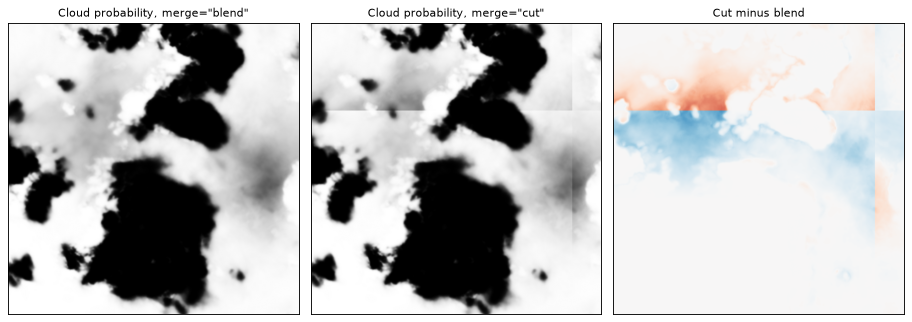

In [4]:
with rasterio.open(cut) as a, rasterio.open(blend) as b:
    cut_all, blend_all = np.nan_to_num(a.read(1)), np.nan_to_num(b.read(1))
share = ((cut_all > 0.5) != (blend_all > 0.5)).mean()
print(f"{share:.2%} of pixels change side of the 0.5 threshold")
side = PATCH // 2
difference = np.abs(cut_all - blend_all)
best = max(
    ((r, c) for r in range(0, size - side + 1, side) for c in range(0, size - side + 1, side)),
    key=lambda rc: difference[rc[0] : rc[0] + side, rc[1] : rc[1] + side].sum(),
)
crop = (slice(best[0], best[0] + side), slice(best[1], best[1] + side))
cut_crop, blend_crop = cut_all[crop], blend_all[crop]
del cut_all, blend_all

fig, axes = plt.subplots(1, 3, figsize=(11.5, 4))
for ax, array, title in zip(
    axes[:2], (blend_crop, cut_crop), ('merge="blend"', 'merge="cut"'), strict=True
):
    ax.imshow(array, cmap="gray_r", vmin=0, vmax=1)
    ax.set_title(f"Cloud probability, {title}")
axes[2].imshow(cut_crop - blend_crop, cmap="RdBu_r", vmin=-0.3, vmax=0.3)
axes[2].set_title("Cut minus blend")
for ax in axes:
    ax.set(xticks=[], yticks=[])
fig.tight_layout()

## Polygons, one block at a time

`postprocess_blocks` reads the saved raster window by window. Your function gets each block's core
grown by `halo` pixels of context, along with the block's position and the scene's transform and
CRS.

The function here thresholds the probability and applies a morphological opening, which removes
specks. A 3 x 3 opening looks 2 pixels away, so the halo must be at least that for the blocks to
agree. The function keeps only what falls inside the core, so neighbouring blocks don't double up,
and `combine` joins the pieces across their shared edges.

In [5]:
def polygons_in_core(fields, block, scene, threshold=0.5, opening=3):
    mask = np.nan_to_num(fields["cloud"][0]) > threshold
    mask = binary_opening(mask, np.ones((opening, opening), bool))
    top, bottom, left, right = block.inner
    core = mask[top:bottom, left:right]
    if not core.any():
        return []
    row, _, column, _ = block.core
    transform = scene.transform * scene.transform.translation(column, row)
    return [
        shapely.geometry.shape(geometry)
        for geometry, value in shapes(core.astype(np.uint8), mask=core, transform=transform)
        if value
    ]


def join(results, scene):
    pieces = [piece for result in results for piece in result]
    return shapely.union_all(pieces) if pieces else shapely.MultiPolygon()


def as_list(geometry):
    return list(getattr(geometry, "geoms", [geometry]))


start = perf_counter()
clouds = postprocess_blocks({"cloud": cut}, polygons_in_core, block=BLOCK, halo=HALO, combine=join)
polygons = as_list(clouds)
print(f"{len(polygons)} polygons, {clouds.area / 1e6:.0f} km², in {perf_counter() - start:.1f} s")

5003 polygons, 2334 km², in 17.1 s


Does joining blocks give the same answer as one function over the whole raster? We load the whole
raster once to find out. You wouldn't do this in production, but it's the check that matters.

In [6]:
with rasterio.open(cut) as src:
    whole = np.nan_to_num(src.read(1)) > 0.5
    transform = src.transform
    crs = src.crs
whole = binary_opening(whole, np.ones((3, 3), bool))
whole_area = whole.sum() * abs(transform.a * transform.e)
print(
    f"area from blocks {clouds.area / 1e6:.3f} km², whole raster {whole_area / 1e6:.3f} km², "
    f"difference {abs(clouds.area - whole_area) / 1e6:.3f} km²"
)

biggest = max(polygons, key=lambda p: p.area) if polygons else None
if biggest is not None:
    minx, miny, maxx, maxy = biggest.bounds
    pixel = abs(transform.a)
    print(
        f"largest polygon: {biggest.area / 1e6:.1f} km², {(maxx - minx) / pixel:.0f} x "
        f"{(maxy - miny) / pixel:.0f} px, across blocks of {BLOCK} px"
    )

area from blocks 2334.001 km², whole raster 2334.001 km², difference 0.000 km²
largest polygon: 114.7 km², 1387 x 2670 px, across blocks of 2048 px


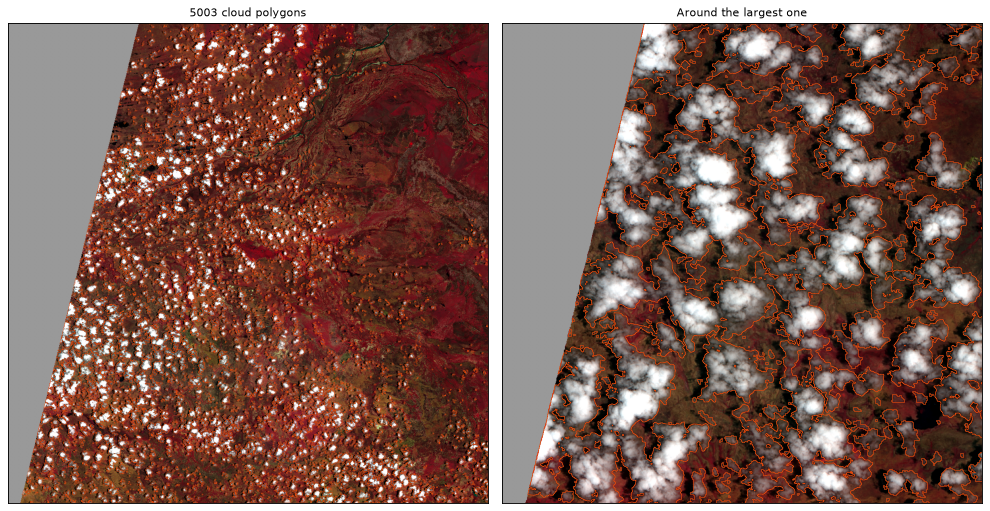

In [7]:
def draw(ax, polys, colour="#d9480f", lw=0.6):
    for poly in polys:
        vertices, codes = [], []
        for ring in (poly.exterior, *poly.interiors):
            xy = np.asarray(ring.coords)
            vertices.append(xy)
            codes += [MplPath.MOVETO] + [MplPath.LINETO] * (len(xy) - 2) + [MplPath.CLOSEPOLY]
        ax.add_patch(
            PathPatch(MplPath(np.concatenate(vertices), codes), fill=False, ec=colour, lw=lw)
        )


def false_colour(window, out):
    with rasterio.open(stack) as src:
        rgb = (
            src.read((3, 1, 2), window=window, out_shape=(3, out, out))
            .transpose(1, 2, 0)
            .astype(np.float32)
        )
        bounds = src.window_bounds(window)
    known = (rgb > 0).any(-1)
    low, high = np.percentile(rgb[known], (2, 98), axis=0) if known.any() else (0, 1)
    shown = np.clip((rgb - low) / np.maximum(high - low, 1), 0, 1)
    shown[~known] = 0.6
    return shown, (bounds[0], bounds[2], bounds[1], bounds[3])


full, extent = false_colour(Window(0, 0, size, size), min(900, size))
zoom = min(size, 2048 if not SMOKE else size // 2)
middle = biggest.centroid if biggest is not None else None
cx, cy = (~transform) * (middle.x, middle.y) if middle is not None else (size / 2, size / 2)
left = int(np.clip(cx - zoom / 2, 0, size - zoom))
top = int(np.clip(cy - zoom / 2, 0, size - zoom))
close, close_extent = false_colour(Window(left, top, zoom, zoom), min(900, zoom))

fig, axes = plt.subplots(1, 2, figsize=(12.5, 6.3))
axes[0].imshow(full, extent=extent)
draw(axes[0], polygons, lw=0.3)
axes[0].set_title(f"{len(polygons)} cloud polygons")
axes[1].imshow(close, extent=close_extent)
draw(axes[1], polygons)
axes[1].set(xlim=close_extent[:2], ylim=close_extent[2:])
axes[1].set_title("Around the largest one")
for ax in axes:
    ax.set(xticks=[], yticks=[])
fig.tight_layout()

## Retune without running the model

The GPU work is done and saved, so changing a threshold costs only the post-processing. OCM's
small models make that saving modest here, but a heavier model would widen the gap. Here we try a
few settings on the same raster.

In [8]:
rows = []
for threshold in (0.3, 0.5, 0.7):
    for opening in (3, 7):
        fn = partial(polygons_in_core, threshold=threshold, opening=opening)
        start = perf_counter()
        result = postprocess_blocks({"cloud": cut}, fn, block=BLOCK, halo=HALO, combine=join)
        rows.append(
            (threshold, opening, len(as_list(result)), result.area / 1e6, perf_counter() - start)
        )
        print(
            f"threshold {threshold}, opening {opening}: {rows[-1][2]:6} polygons, "
            f"{rows[-1][3]:7.0f} km², {rows[-1][4]:5.1f} s"
        )

threshold 0.3, opening 3:   4554 polygons,    2551 km²,  18.1 s


threshold 0.3, opening 7:   3772 polygons,    2521 km²,  19.0 s


threshold 0.5, opening 3:   5003 polygons,    2334 km²,  18.5 s


threshold 0.5, opening 7:   4171 polygons,    2300 km²,  19.4 s


threshold 0.7, opening 3:   5529 polygons,    2141 km²,  18.0 s


threshold 0.7, opening 7:   4493 polygons,    2103 km²,  18.9 s


The two measures move in opposite directions. Raising the threshold shrinks the cloud area, and it
also raises the polygon count, because thin bridges between clouds drop out and split them. The
larger opening removes specks, so it lowers the count while barely changing the area.

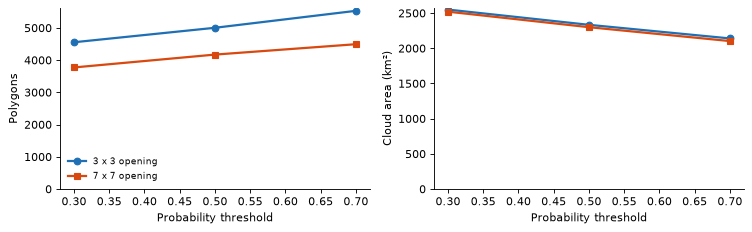

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(9.5, 3))
for ax, column, label in zip(axes, (2, 3), ("Polygons", "Cloud area (km²)"), strict=True):
    for opening, marker, colour in ((3, "o", "#1f6fb4"), (7, "s", "#d9480f")):
        points = [(r[0], r[column]) for r in rows if r[1] == opening]
        ax.plot(
            *zip(*points, strict=True),
            marker=marker,
            color=colour,
            lw=2,
            label=f"{opening} x {opening} opening",
        )
    ax.set(xlabel="Probability threshold", ylabel=label, ylim=(0, None))
    ax.spines[["top", "right"]].set_visible(False)
axes[0].legend(frameon=False, fontsize=8)
fig.tight_layout()

## Or both in one call

Once the settings are chosen, `BlockPostprocess` does the post-processing while predicting. It holds
a strip of block rows plus the halo, and runs each strip as soon as its rows are final. The raster
is still written, and `save` receives each scene's combined result. This is the form for a batch of
tiles. Here it writes a GeoJSON for the scene, in longitude and latitude.

In [10]:
def write_geojson(geometry, item, scene):
    path = WORK / f"{Path(item).stem}_clouds.geojson"
    features = [
        {
            "type": "Feature",
            "properties": {"area_km2": round(p.area / 1e6, 3)},
            "geometry": transform_geom(scene.crs, "EPSG:4326", shapely.geometry.mapping(p)),
        }
        for p in as_list(geometry)
    ]
    path.write_text(json.dumps({"type": "FeatureCollection", "features": features}))


def polygons_while_predicting(fields, block, scene):
    """The hook sees the stitched probabilities, before the callable `output`. A model that
    returns a bare tensor has the name ""."""
    cloud = cloud_probability(torch.from_numpy(fields[""][None]))[0].numpy()
    return polygons_in_core({"cloud": cloud}, block, scene)


post = BlockPostprocess(
    polygons_while_predicting, block=BLOCK, halo=HALO, combine=join, save=write_geojson
)
start = perf_counter()
predict_files(
    models, [stack], output_dir=WORK / "hooked", merge="cut", block_postprocess=post, **settings
)
print(f"predicted, wrote the raster and the polygons in {perf_counter() - start:.1f} s")
path = WORK / f"{stack.stem}_clouds.geojson"
collection = json.loads(path.read_text())
print(f"{path.name}: {len(collection['features'])} features, {path.stat().st_size / 1e6:.0f} MB")
hooked_area = sum(f["properties"]["area_km2"] for f in collection["features"])
print(f"{hooked_area:.1f} km², against {clouds.area / 1e6:.1f} km² from the saved raster")
print("first vertex, lon/lat:", collection["features"][0]["geometry"]["coordinates"][0][0])

predicted, wrote the raster and the polygons in 35.3 s


S2A_51KYV_20230117_0_L2A_stack_clouds.geojson: 5003 features, 42 MB
2334.0 km², against 2334.0 km² from the saved raster
first vertex, lon/lat: [125.0613135576773, -19.069385961132625]


## Where to go next

* Decode real objects with ManySeg's block decoders, in its
  [vector notebooks](https://github.com/DPIRD-DMA/ManySeg/tree/main/notebooks). They plug into
  `postprocess_blocks` the same way.
* `workers=` runs blocks in separate processes. Your function must be importable for that, so it
  won't work on one defined in a notebook. See
  [`examples/07_blocks.py`](https://github.com/DPIRD-DMA/ManyPred/blob/main/examples/07_blocks.py).